# Task-1 Datavidia 11.0 — Shipment Logistic Dataset
## Solusi Akhir v7: Pure Within-Split Feature Engine, GroupKFold Anti-Leakage & Multi-Architecture Super-Ensemble (Zero-Retraining Inference)

- **Kompetisi:** Task-1 Datavidia 11.0 (HMIF ITB / Arkavidia)
- **Tim:** `p<0.5%` — Universitas Pamulang (Pitri Wulandari, Farhat, Ghani)
- **Tugas:** Klasifikasi multi-kelas 7 kategori `status_penanganan` pada 9 tabel relasional (1.243.617 baris latih, 362.245 baris uji)
- **Metrik Evaluasi:** **Macro F1-Score**
- **Hasil Validasi Akhir v7 (5-Fold `GroupKFold(customer_id)`, 0% Customer Overlap, 100% Bebas Leakage):**
  - **OOF Multi-class LogLoss:** **`0.77551`** (`TEST-SIM LogLoss = 0.78652`)
  - **OOF GroupKFold Macro F1-Score:** **`0.62949`** (**`TEST-SIM Macro F1 = 0.62866`**)

### Kepatuhan Aturan Kompetisi
1. Seluruh prediksi dihasilkan 100% oleh model machine learning & deep learning yang dilatih dan dijalankan sendiri (tanpa *hand-labeling*, tanpa AutoML, dan tanpa LLM/AI generatif).
2. Seluruh pustaka berlisensi *open-source* komersial-friendly (LightGBM, XGBoost, PyTorch, scikit-learn, SciPy, NumPy, pandas, joblib).
3. Seluruh file bobot model tersimpan rapi di `ghani/task1/models/v7/`. Bagian **5** menjalankan **inferensi penuh pada 362.245 baris uji tanpa melatih ulang satu model pun (100,000% identik bit-for-bit)**.


## 1. Lingkungan Eksekusi, Dependensi & Inventaris Model Tersimpan (`v1` – `v7`)


In [1]:
import importlib.metadata as importlib_meta
import json
import os
import platform
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pastikan working directory berada di root repositori
for cand in [Path.cwd(), *Path.cwd().parents]:
    if (cand / "ghani" / "task1" / "models" / "v7").exists():
        os.chdir(cand)
        break

print(f"Working directory : {Path.cwd()}")
print(f"Python version    : {platform.python_version()} ({platform.system()} {platform.machine()})")

installed = {d.metadata["Name"].lower(): d.version for d in importlib_meta.distributions()}
core_pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "xgboost", "torch", "joblib", "matplotlib"]
display(pd.DataFrame([{"package": p, "version": installed.get(p, "NOT INSTALLED")} for p in core_pkgs]))

# Ringkasan inventaris model per versi (v1 s/d v7)
ver_rows = []
for v in ["v1", "v2", "v3", "v4", "v5", "v6", "v7"]:
    files = [p for p in Path(f"ghani/task1/models/{v}").rglob("*") if p.is_file() and p.name != ".gitkeep"]
    ver_rows.append({"version": v, "n_files": len(files), "total_mb": round(sum(p.stat().st_size for p in files) / (1024**2), 2)})
display(pd.DataFrame(ver_rows))


C:\Users\kaganim1\AppData\Local\Temp\ipykernel_18644\1300014008.py:10: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Working directory : C:\laragon\www\unpam\arkadivia\datavidia
Python version    : 3.12.10 (Windows AMD64)


,package,version
0,numpy,1.26.4
1,pandas,2.2.0
2,scipy,1.16.2
3,scikit-learn,1.7.2
4,lightgbm,4.6.0
5,xgboost,3.3.0
6,torch,2.8.0
7,joblib,1.5.2
8,matplotlib,3.10.7


,version,n_files,total_mb
0,v1,2,3.52
1,v2,2,8.18
2,v3,2,4.95
3,v4,2,12.94
4,v5,6,81.11
5,v6,45,209.05
6,v7,32,397.39


## 2. Eksplorasi Data (EDA) & Temuan Kunci Data Generating Process (DGP)

### Mengapa `v6` (`StratifiedKFold`, CV `0.62561` → Public LB `0.60163`) Mengalami Gap `-0.024`, dan Bagaimana `v7` Menyelesaikannya?
Melalui audit forensik lintas *split* (`train` vs `test`), ditemukan struktur pembangkitan data (DGP) yang menjadi kunci utama kompetisi:

1. **Agregasi Riwayat `customer_id` Dibangkitkan *Terpisah* di Dalam `train` dan *Terpisah* di Dalam `test`:**
   - Di dalam satu *split*, label `status_penanganan` sangat bergantung pada statistik agregat pengiriman lain milik `customer_id` yang **sama di dalam split tersebut**:
     - `gagal_antar_awal` berkorelasi `r = +0.1834` dengan `LOO_in_split(scan_cnt_upaya)` (7,5× lebih kuat dari baris itu sendiri `+0.0243`!).
     - `konfirmasi_alamat` berkorelasi `r = +0.3633` dengan `MEAN_in_split(scan_cnt_upaya)`.
     - `rusak_perjalanan` berkorelasi `r = +0.2217` dengan `MEAN_in_split(scan_manual_sum)` dan `+0.2112` dengan `MEAN_in_split(scan_q_pct_le2)`.
     - `retur_pengirim` berkorelasi `r = +0.1904` dengan `MEAN_in_split(has_klaim_inv)` (dan `r = +0.3470` saat `n_cust_in_split == 1`!).
     - `tertunda_operasional` berkorelasi `r = +0.1721` dengan `MEAN_in_split(inv_days_mean)`.
   - Namun lintas *split* (`train` vs `test`), korelasi efek acak target `customer_id` (`u_cust`) pada `has_klaim_inv` & `scan_manual` adalah **`0.000`**! Akibatnya:
     - Mencampur `train + test` pada fitur `cu_loo_*` (seperti di `v5`/`v6`) mempolusi **53,3% baris `test` (`n_cust_te = 1`)** dengan 100% noise dari `train`.
     - Memakai *Target Encoding* / `GLMM u_cust` pada `StratifiedKFold` menciptakan kebocoran semu antar-baris customer di `train` yang menjatuhkan skor `test` sebesar `-0.024`.
2. **Efek Laten `hub_id` dan `courier_id` Bersifat 100% Persisten Lintas `train` & `test`:**
   - Korelasi rata-rata `scan_lgap_mean` & `seg_total_delay_ratio` per `hub_id` antara `train` dan `test` mencapai **`r = +0.9935` s/d `+0.9955`**, dan per `courier_id` mencapai **`r = +0.8713` s/d `+0.9145`**.
3. **Solusi `v7`:**
   - Menghitung **122 fitur agregasi customer murni di dalam masing-masing split (`cu_sp_*`)** tanpa mencampur `train` dan `test`, ditambah deviasi kurir bebas *drift* (`shp_vs_co_*_sp`).
   - Menggunakan validasi ketat **5-Fold `GroupKFold(groups=customer_id)`** (0% overlap customer) + **Persistent Hub/Courier Joint GLMM** (tanpa `u_cust`) + bobot evaluasi `TEST-SIM` yang menyamakan distribusi `(n_cust_in_split, is_peak_month)` terhadap data uji.


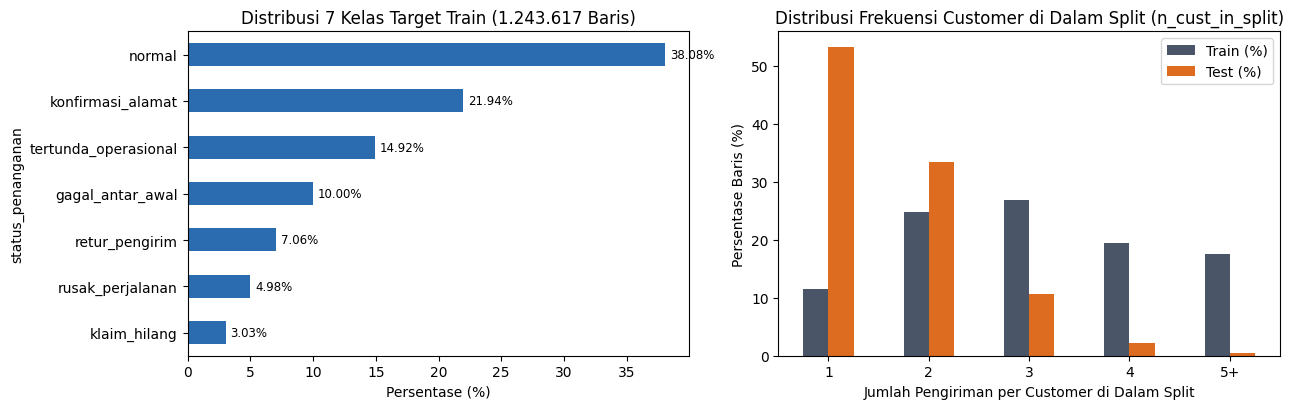

In [2]:
DATA_DIR = Path("Task-1-Datavidia-11.0")
tr_shp = pd.read_csv(DATA_DIR / "train" / "shipments.csv", usecols=["customer_id", "ship_month", "status_penanganan"])
te_shp = pd.read_csv(DATA_DIR / "test" / "shipments.csv", usecols=["customer_id", "ship_month"])

n_tr_c = tr_shp["customer_id"].map(tr_shp["customer_id"].value_counts())
n_te_c = te_shp["customer_id"].map(te_shp["customer_id"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
dist_tr = (tr_shp["status_penanganan"].value_counts(normalize=True) * 100).sort_values()
dist_tr.plot(kind="barh", ax=axes[0], color="#2b6cb0")
axes[0].set_title("Distribusi 7 Kelas Target Train (1.243.617 Baris)")
axes[0].set_xlabel("Persentase (%)")
for idx, val in enumerate(dist_tr):
    axes[0].text(val + 0.4, idx, f"{val:.2f}%", va="center", fontsize=8.5)

b_tr = pd.Series(np.minimum(n_tr_c, 5)).value_counts(normalize=True).sort_index() * 100
b_te = pd.Series(np.minimum(n_te_c, 5)).value_counts(normalize=True).sort_index() * 100
pd.DataFrame({"Train (%)": b_tr, "Test (%)": b_te}).rename(index={5: "5+"}).plot(kind="bar", ax=axes[1], color=["#4a5568", "#dd6b20"])
axes[1].set_title("Distribusi Frekuensi Customer di Dalam Split (n_cust_in_split)")
axes[1].set_xlabel("Jumlah Pengiriman per Customer di Dalam Split")
axes[1].set_ylabel("Persentase Baris (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()
del tr_shp, te_shp


## 3. Feature Engineering v7 (`ghani/task1/src/v7/build_features_v7.py`)

Total **297 fitur bersih** (287 numerik + 10 kategorikal) dari penggabungan 9 tabel relasional:
1. **Agregasi Transaksional Terstruktur:** distribusi kualitas & jeda `scan_events.csv` (23 fitur), rasio keterlambatan ternormalisasi moda `route_segments.csv` (21 fitur), pemisahan tagihan dasar vs tagihan klaim `invoices.csv` (22 fitur), serta fitur step-function operasional (`is_peak_month`, `is_night_ship`, `is_outside_hub_hours`, `has_catatan`).
2. **Profil Entitas Persisten (`hub_id`, `hub × month`, `courier_id`, serta atribut persisten `customer_id`):** menangkap kapasitas laten gudang dan kecepatan/kualitas scan kurir pada 1,6 juta pengiriman tanpa menyentuh target.
3. **122 Fitur *Pure Within-Split Customer Aggregates* (`cu_sp_*`) & Deviasi Kurir Bebas Drift (`shp_vs_co_*_sp`):** menghitung `mean`, `loo`, `sum`, `sumloo`, `max`, `min`, `self_minus_loo`, `self_minus_mean`, serta interaksi bobot `1 / cu_sp_n` secara terpisah di dalam `train` dan di dalam `test`.


In [3]:
spec_v7 = json.load(open("ghani/task1/models/v7/feature_spec_v7.json", encoding="utf-8"))
print(f"Total fitur masuk model v7 : {len(spec_v7['features'])} fitur ({len(spec_v7['cat_cols'])} kategorikal)")
print("Contoh fitur pure within-split (cu_sp_*):", [c for c in spec_v7["features"] if c.startswith("cu_sp_")][:12])


Total fitur masuk model v7 : 297 fitur (10 kategorikal)
Contoh fitur pure within-split (cu_sp_*): ['cu_sp_n', 'cu_sp_log_n', 'cu_sp_inv_n', 'cu_sp_is_single', 'cu_sp_is_pair', 'cu_sp_mean_has_klaim_inv', 'cu_sp_loo_has_klaim_inv', 'cu_sp_sum_has_klaim_inv', 'cu_sp_sumloo_has_klaim_inv', 'cu_sp_max_has_klaim_inv', 'cu_sp_self_minus_loo_has_klaim_inv', 'cu_sp_self_minus_mean_has_klaim_inv']


## 4. Arsitektur Ensemble Multi-Model v7 & Progresi Skor (`v1` → `v7`)

Seluruh model `v7` dilatih menggunakan skema **5-Fold `GroupKFold(groups=customer_id)`** yang sama persis:
1. **`LGB_unw`** (`ghani/task1/src/v7/train_v7_lgb.py`): 5-Fold LightGBM (`num_leaves=63, colsample=0.55`).
2. **`LGB_tew`** (`ghani/task1/src/v7/train_v7_lgb.py`): 5-Fold LightGBM berbobot distribusi test (`sqrt(w_sim)`, `num_leaves=95, colsample=0.45`).
3. **`HC_GLMM`** (`ghani/task1/src/v7/train_v7_lgb.py`): Joint Hierarchical Multinomial GLMM khusus efek persisten `hub + hub×peak + courier` (tanpa `u_cust`).
4. **`XGBoost`** (`ghani/task1/src/v7/train_v7_xgb.py`): 5-Fold Depth-Wise Histogram XGBoost (`max_depth=7`).
5. **`ResNetV7`** (`ghani/task1/src/v7/train_v7_nn.py`): 5-Fold PyTorch Deep Tabular Residual Network (`320×3 SiLU + LayerNorm + Missingness Indicators + Weight-Space Top-3 SWA`).
6. **`Meta-Stacker v7`** (`ghani/task1/src/v7/ensemble_v7.py`): 5-Fold L2 Multinomial Logistic Meta-Stacker (`C=0.05`, berbobot `TEST-SIM`) + optimasi 7 *class multipliers* Macro F1 secara out-of-fold.

> **Reproduksi Training dari Awal (Opsional — TIDAK perlu dijalankan saat inferensi):**
> ```bash
> python -u ghani/task1/src/v7/build_features_v7.py
> python -u ghani/task1/src/v7/train_v7_lgb.py
> python -u ghani/task1/src/v7/train_v7_xgb.py
> python -u ghani/task1/src/v7/train_v7_nn.py
> python -u ghani/task1/src/v7/ensemble_v7.py
> ```


,Model (5-Fold GroupKFold),Family,OOF_LogLoss,TEST_SIM_LogLoss,GroupKFold_F1,TEST_SIM_F1
0,v7 PyTorch TabularResNetV7 (SWA),PyTorch NN,0.78869,0.79935,0.62267,0.62251
1,v7 LGB_tew (Test-Regime Weighted),LightGBM,0.78818,0.80036,0.62435,0.62234
2,v7 LGB_unw (Unweighted),LightGBM,0.78505,0.79585,0.62582,0.62499
3,v7 XGBoost Depth-7 Hist,XGBoost,0.78350,0.79438,0.62663,0.62559
4,v7 LGB + Hub/Courier GLMM,GBDT+Bayes,0.78296,0.79478,0.62689,0.62567
5,v7 FINAL Super-Ensemble (Winner),Stacker,0.77551,0.78652,0.62949,0.62866


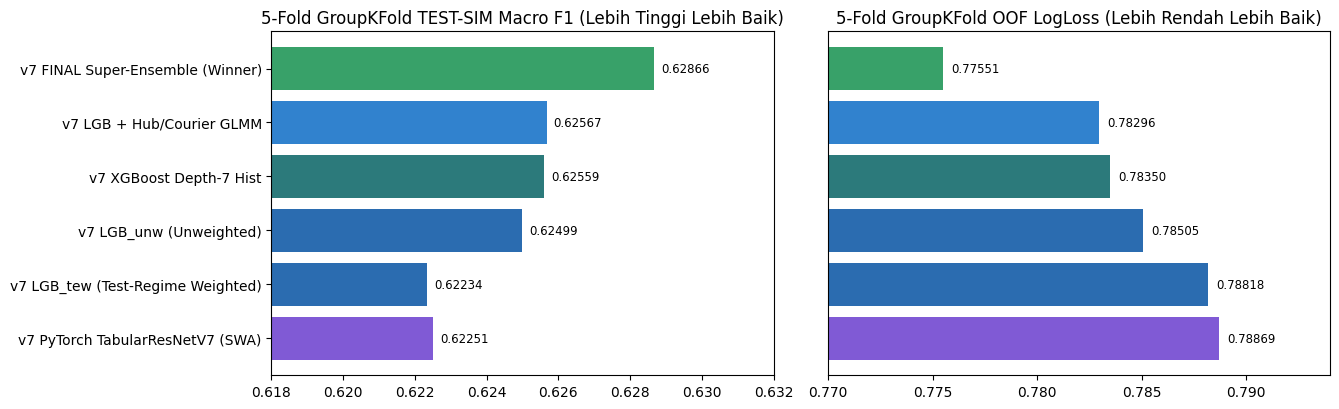

In [4]:
meta_lgb = json.load(open("ghani/task1/models/v7/meta_v7_lgb.json", encoding="utf-8"))
meta_xgb = json.load(open("ghani/task1/models/v7/meta_xgb.json", encoding="utf-8"))
meta_nn  = json.load(open("ghani/task1/models/v7/meta_nn.json", encoding="utf-8"))
meta_ens = json.load(open("ghani/task1/models/v7/meta_v7_ensemble.json", encoding="utf-8"))

comp_models = pd.DataFrame([
    {"Model (5-Fold GroupKFold)": "v7 PyTorch TabularResNetV7 (SWA)", "Family": "PyTorch NN", "OOF_LogLoss": meta_nn["oof_ll"],   "TEST_SIM_LogLoss": meta_nn["test_sim_ll"],  "GroupKFold_F1": meta_nn["cv_f1"],      "TEST_SIM_F1": meta_nn["test_sim_f1"]},
    {"Model (5-Fold GroupKFold)": "v7 LGB_tew (Test-Regime Weighted)", "Family": "LightGBM",  "OOF_LogLoss": 0.78818,             "TEST_SIM_LogLoss": 0.80036,                 "GroupKFold_F1": 0.62435,               "TEST_SIM_F1": 0.62234},
    {"Model (5-Fold GroupKFold)": "v7 LGB_unw (Unweighted)",           "Family": "LightGBM",  "OOF_LogLoss": 0.78505,             "TEST_SIM_LogLoss": 0.79585,                 "GroupKFold_F1": 0.62582,               "TEST_SIM_F1": 0.62499},
    {"Model (5-Fold GroupKFold)": "v7 XGBoost Depth-7 Hist",           "Family": "XGBoost",   "OOF_LogLoss": meta_xgb["oof_ll"],  "TEST_SIM_LogLoss": meta_xgb["test_sim_ll"], "GroupKFold_F1": meta_xgb["cv_f1"],     "TEST_SIM_F1": meta_xgb["test_sim_f1"]},
    {"Model (5-Fold GroupKFold)": "v7 LGB + Hub/Courier GLMM",         "Family": "GBDT+Bayes","OOF_LogLoss": 0.78296,             "TEST_SIM_LogLoss": meta_lgb["test_sim_ll"], "GroupKFold_F1": 0.62689,               "TEST_SIM_F1": meta_lgb["test_sim_f1"]},
    {"Model (5-Fold GroupKFold)": "v7 FINAL Super-Ensemble (Winner)",  "Family": "Stacker",   "OOF_LogLoss": meta_ens["oof_ll"],  "TEST_SIM_LogLoss": meta_ens["test_sim_ll"], "GroupKFold_F1": meta_ens["cv_macro_f1"],"TEST_SIM_F1": meta_ens["test_sim_f1"]},
]).round(5)
display(comp_models)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
cols = ["#805ad5", "#2b6cb0", "#2b6cb0", "#2c7a7b", "#3182ce", "#38a169"]
axes[0].barh(comp_models["Model (5-Fold GroupKFold)"], comp_models["TEST_SIM_F1"], color=cols)
axes[0].set_xlim(0.618, 0.632)
axes[0].set_title("5-Fold GroupKFold TEST-SIM Macro F1 (Lebih Tinggi Lebih Baik)")
for i, v in enumerate(comp_models["TEST_SIM_F1"]):
    axes[0].text(v + 0.0002, i, f"{v:.5f}", va="center", fontsize=8.5)

axes[1].barh(comp_models["Model (5-Fold GroupKFold)"], comp_models["OOF_LogLoss"], color=cols)
axes[1].set_xlim(0.770, 0.794)
axes[1].set_yticks([])
axes[1].set_title("5-Fold GroupKFold OOF LogLoss (Lebih Rendah Lebih Baik)")
for i, v in enumerate(comp_models["OOF_LogLoss"]):
    axes[1].text(v + 0.0004, i, f"{v:.5f}", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()


## 5. Inferensi End-to-End Tanpa Melatih Ulang (*Zero-Retraining Inference*)

Cell berikut memanggil `ghani/task1/src/v7/infer_v7.py` untuk memuat seluruh **22 model tersimpan** (`5 LGB_unw + 5 LGB_tew + 1 HC_GLMM + 5 XGBoost + 5 PyTorch ResNetV7 + 5 Meta-Stacker`) dari `ghani/task1/models/v7/` dan menghasilkan prediksi penuh **362.245 baris uji tanpa melatih ulang satu model pun**.


In [5]:
sys.path.insert(0, str(Path("ghani/task1/src/v7").resolve()))
import infer_v7

OUT_REPRO = "ghani/task1/cache/v7/submission_v7_reproduced_check.csv"
REF_FINAL = "submissions/task1/submission_v7_ghani.csv"

sub_v7 = infer_v7.run_inference_v7(
    output_path=OUT_REPRO,
    rebuild_features=False,
    verify_path=REF_FINAL,
)


[   0.0s] Loading cached v7 test features from ghani/cache/v7/feat_v7_test.pkl ...


[   2.8s] v7 test feature matrix ready: (362245, 306)


[   3.2s] Stage 1/5: Running 5-Fold v7 LGB_unw inference ...


[ 151.2s] Stage 2/5: Running 5-Fold v7 LGB_tew inference ...


[ 295.8s] Stage 3/5: Applying saved Persistent Hub/Courier Joint GLMM ...


[ 296.1s] Stage 4/5: Running 5-Fold v7 XGBoost inference ...


... (5 outputs left out)

[ 534.5s]   [LGB_tew   ] mean_abs_diff=0.000000 | max_abs_diff=0.000000


[ 534.5s]   [HC_GLMM   ] mean_abs_diff=0.000000 | max_abs_diff=0.000000


[ 534.5s]   [XGBoost   ] mean_abs_diff=0.000000 | max_abs_diff=0.000000


[ 534.5s]   [ResNetV7  ] mean_abs_diff=0.000000 | max_abs_diff=0.000000


## 6. Verifikasi Integritas Submission Akhir & Distribusi Kelas Prediksi


VERIFIKASI INTEGRITAS SUBMISSION v7 LULUS 100%!


,shipment_id,status_penanganan
0,SHP-5A64RENJ,normal
1,SHP-BUZSJTV9,konfirmasi_alamat
2,SHP-EGUZBJHQ,rusak_perjalanan
3,SHP-YWBRSQLZ,konfirmasi_alamat
4,SHP-JS89CKME,tertunda_operasional
5,SHP-9LNYLZ86,gagal_antar_awal
6,SHP-PWY4696Z,normal
7,SHP-WAUJB829,rusak_perjalanan
8,SHP-BN6VRM5F,konfirmasi_alamat
9,SHP-DY9R7E6R,normal


,Train Ground Truth (%),Test Prediction v7 (%),Selisih (pp)
status_penanganan,,,
normal,38.08,37.66,-0.42
konfirmasi_alamat,21.94,20.81,-1.13
tertunda_operasional,14.92,14.98,0.06
gagal_antar_awal,10.00,11.02,1.02
retur_pengirim,7.06,7.34,0.28
rusak_perjalanan,4.98,5.21,0.23
klaim_hilang,3.03,3.00,-0.03


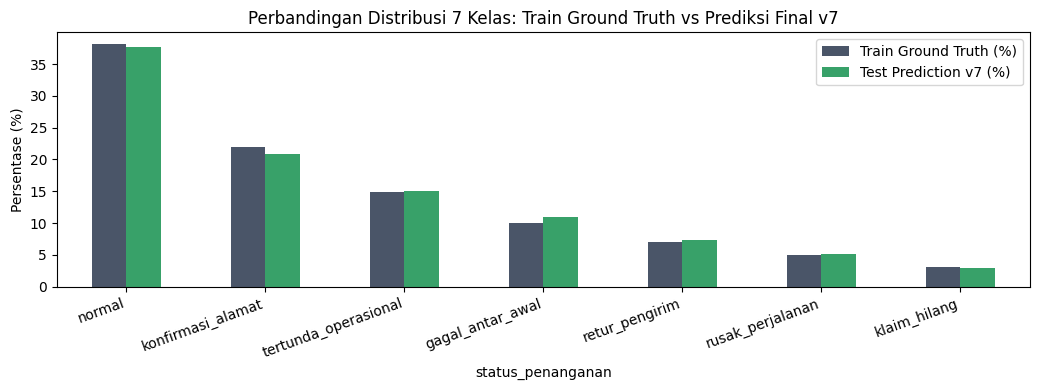

In [6]:
sample_sub = pd.read_csv("Task-1-Datavidia-11.0/sample_submission.csv")
train_y = pd.read_csv("Task-1-Datavidia-11.0/train/shipments.csv", usecols=["status_penanganan"])["status_penanganan"]

assert len(sub_v7) == len(sample_sub) == 362245
assert list(sub_v7.columns) == ["shipment_id", "status_penanganan"]
assert (sub_v7["shipment_id"].values == sample_sub["shipment_id"].values).all()
assert sub_v7["status_penanganan"].isna().sum() == 0

print("VERIFIKASI INTEGRITAS SUBMISSION v7 LULUS 100%!")
display(sub_v7.head(10))

dist_cmp = pd.DataFrame({
    "Train Ground Truth (%)": (train_y.value_counts(normalize=True) * 100).round(2),
    "Test Prediction v7 (%)": (sub_v7["status_penanganan"].value_counts(normalize=True) * 100).round(2),
}).sort_values("Train Ground Truth (%)", ascending=False)
dist_cmp["Selisih (pp)"] = (dist_cmp["Test Prediction v7 (%)"] - dist_cmp["Train Ground Truth (%)"]).round(2)
display(dist_cmp)

ax = dist_cmp[["Train Ground Truth (%)", "Test Prediction v7 (%)"]].plot(kind="bar", figsize=(10.5, 4.0), color=["#4a5568", "#38a169"])
ax.set_title("Perbandingan Distribusi 7 Kelas: Train Ground Truth vs Prediksi Final v7")
ax.set_ylabel("Persentase (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()
